# Preprocessing: raw scans -> train / val / test

Turns the eCommons map scans into de-duplicated train / val / test folders, plus a `manifest.csv` that every later notebook reads labels from.

1. Settings
2. Helper functions
3. Load labels and give each image a "work" key
4. Find duplicate scans of the same map, and review the merges
5. Build split groups (same work or same map)
6. Stratified group split, one scan per map
7. Pad, resize, denoise, save images. Extra scans of train maps come back as "rescans" (natural augmentation)
8. Write the manifest and summaries
9. Spot check

Run top to bottom. **Nothing is written to disk until section 7**, which deletes and rebuilds `data/processed/` (including any augmentation, so re-run `augment.ipynb` afterwards). A full run takes a few minutes; the denoising step is most of it.

## 1. Settings
Everything you might want to change lives in the second cell. Paths are found relative to the repo root, so the notebook works on anyone's machine.

In [1]:
import json
import os
import re
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw

# A few fold-out maps are >100 megapixels. This is a trusted dataset, so turn off
# Pillow's decompression-bomb guard (it raises an error above ~179 MP).
Image.MAX_IMAGE_PIXELS = None

In [2]:
# ---- Paths ---------------------------------------------------------------------
# Repo root = first folder at or above this notebook that contains .git
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()), None)
assert ROOT is not None, "Open this notebook from inside the 281project repo"
RAW = ROOT / "data" / "ecommons"
IMG_ROOT = RAW / "final_maps" / "Bax_LiteratureMaps_final_maps"  # the "Image" column is relative to this
LABELS_CSV = RAW / "Gemini" / "Bax_LiteratureMaps_Gemini" / "Gemini_fict-scale_full.csv"
MARC_CSV = RAW / "MARC" / "Bax_LiteratureMaps_MARC" / "MARC_info_parallel.csv"
OUT_DIR = ROOT / "data" / "processed"

# ---- Split ---------------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
SEED = 281

# ---- De-duplication ------------------------------------------------------------
DEDUP = True                    # False = keep every scan in every split (one reprinted map then
                                # counts many times in val/test too - not recommended)
RESCANS_AS_AUGMENTATION = True  # True = extra scans of a TRAIN map become extra training rows
                                # (variant "rescan"); False = they're dropped. Val/test always
                                # keep one scan per map either way.
MAX_RESCANS_PER_MAP = 4         # cap, so a map scanned 23 times doesn't count 23 times.
                                # Keep it <= MAX_COPIES_PER_MAP in augment.ipynb.
PHASH_MAX_DIST = 10             # Hamming distance (out of 64 bits) at or below which two scans are the same map
HASH_CROP = 0.10                # fraction of each edge ignored when hashing (clips, stickers, gutters)

# ---- Resize / pad --------------------------------------------------------------
TARGET_HEIGHT = 1024      # px; width follows from the train median aspect ratio (~690 x 1024).
                          # None = train median height (~2400 px): ~5x the pixels, slower downstream
ROTATE_LANDSCAPE = False  # True = turn landscape fold-outs to portrait instead of padding them into a thin band
PAD_MODE = "paper"        # "paper" (scan's own border color), "white", or "black" (adds a hard edge HOG will see)

# ---- Denoise -------------------------------------------------------------------
DENOISE = True
DENOISE_STRENGTH = 3      # 3 = light; ~10 starts erasing the fine hatching that LBP relies on

# ---- Misc ----------------------------------------------------------------------
OUTPUT_EXT = ".png"       # lossless, so texture features don't learn JPEG block artifacts
N_WORKERS = os.cpu_count() or 4
CLASS_NAMES = {0: "small", 1: "medium", 2: "large"}
EXCLUDE = {"32000002642652_00000033.jpg", "39015030849908_00000219.jpg"}  # authors: cartoons containing a map

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1) < 1e-6, "split fractions must sum to 1"
print("Repo root:", ROOT)

Repo root: /home/uselessbian/281/281project


## 2. Helper functions
`parallel_map` runs a function over many images on a thread pool. Threads rather than processes because multiprocessing can't find functions defined in a notebook on Windows or macOS. OpenCV and Pillow release Python's lock during the heavy work, so threads still use every core.

`UnionFind` merges items into connected groups: after `union(a, b)` and `union(b, c)`, items a, b and c share one group id. It's used twice, for duplicate clusters and for split groups.

In [3]:
def parallel_map(fn, items, desc="working"):
    """fn over items on a thread pool, results in order, with a progress line."""
    items, out, t0 = list(items), [], time.time()
    step = max(1, len(items) // 20)
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        for i, result in enumerate(pool.map(fn, items), 1):
            out.append(result)
            if i % step == 0 or i == len(items):
                print(f"\r{desc}: {i}/{len(items)} ({time.time() - t0:.0f}s)", end="")
    print()
    return out


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra

    def component_ids(self):
        """Group id 0..k-1 for every item."""
        return np.unique([self.find(i) for i in range(len(self.parent))], return_inverse=True)[1]


def normalize_text(value):
    """'Treasure island /' and 'Treasure Island.' both -> 'treasure island'."""
    if pd.isna(value):
        return ""
    s = str(value).lower().replace("from old catalog", " ")
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    s = re.sub(r"\bpseud\b", " ", s)  # "Twain, Mark [pseud.]" == "Twain, Mark"
    return re.sub(r"\s+", " ", s).strip()

Image helpers. Padding uses the scan's own paper color (the median of its outer 3% of pixels), so the padding doesn't create an artificial edge for HOG to pick up. `thumbnail` decodes big JPEGs at reduced scale, so the review cells stay fast.

In [4]:
def border_color(img, frac=0.03):
    """Median color of the outer `frac` of the image - an estimate of the paper color."""
    h, w = img.shape[:2]
    b = max(1, int(min(h, w) * frac))
    edges = np.concatenate([img[:b].reshape(-1, 3), img[-b:].reshape(-1, 3),
                            img[:, :b].reshape(-1, 3), img[:, -b:].reshape(-1, 3)])
    return tuple(int(v) for v in np.median(edges, axis=0))


def pad_to_aspect(img, ratio_hw, mode):
    """Center the image on a canvas whose height / width == ratio_hw (no stretching)."""
    h, w = img.shape[:2]
    color = {"white": (255, 255, 255), "black": (0, 0, 0)}.get(mode) or border_color(img)
    if h / w < ratio_hw:  # too wide -> pad top and bottom
        pad = int(round(w * ratio_hw)) - h
        return cv2.copyMakeBorder(img, pad // 2, pad - pad // 2, 0, 0, cv2.BORDER_CONSTANT, value=color)
    pad = int(round(h / ratio_hw)) - w  # too tall -> pad left and right
    return cv2.copyMakeBorder(img, 0, 0, pad // 2, pad - pad // 2, cv2.BORDER_CONSTANT, value=color)


def thumbnail(path, size=(150, 220)):
    """Small RGB preview of an image file."""
    with Image.open(path) as im:
        im.draft("RGB", size)
        im = im.convert("RGB")
    im.thumbnail(size)
    return im

## 3. Load labels and work keys
- Labels are the `Scale` column of the Gemini CSV: 0 = small, 1 = medium, 2 = large. The two maps the dataset authors flagged are dropped.
- Filenames are `<book id>_<page>.jpg`, so the book ID is everything before the last `_`.
- A **work key** is the MARC title + author, lowercased with punctuation stripped, so different libraries' scans of the same novel match. Books missing from MARC fall back to their own book ID.

In [5]:
labels = pd.read_csv(LABELS_CSV)
df = pd.DataFrame({
    "filename": labels["Image"].str.split("/").str[-1],
    "label": labels["Scale"].astype(int),
    "fictionality": labels["Fictionality"],
    "src_path": labels["Image"].map(lambda p: str(IMG_ROOT / p)),
})
n_labeled = len(df)
df = df[~df["filename"].isin(EXCLUDE)].copy()
df["image_id"] = df["filename"].str.rsplit(".", n=1).str[0]
df["book_id"] = df["image_id"].str.rsplit("_", n=1).str[0]  # last "_" in case an id ever contains one

missing = ~df["src_path"].map(os.path.exists)
assert not missing.all(), f"No images under {IMG_ROOT} - run scripts/download_dataset.py first"
if missing.any():
    print(f"WARNING: {missing.sum()} labeled images not on disk, dropping them")
df = df[~missing]

if MARC_CSV.exists():
    marc = pd.read_csv(MARC_CSV, usecols=["htid", "_245_a", "_100_a"], dtype=str)
    marc["book_id"] = marc["htid"].str.split("/").str[-1]
    df = df.merge(marc.drop_duplicates("book_id")[["book_id", "_245_a", "_100_a"]], on="book_id", how="left")
    title, author = df["_245_a"].map(normalize_text), df["_100_a"].map(normalize_text)
    df["work_key"] = np.where(title != "", title + " | " + author, "book:" + df["book_id"])
    df = df.drop(columns=["_245_a", "_100_a"])
    print(f"MARC title found for {(title != '').mean():.0%} of images")
else:
    print("WARNING: MARC file not found - grouping by scanned volume only")
    df["work_key"] = "book:" + df["book_id"]
df = df.reset_index(drop=True)

print(f"{n_labeled} labeled images, {n_labeled - len(df)} excluded -> {len(df)}")
print(f"{df['book_id'].nunique()} scanned volumes -> {df['work_key'].nunique()} works")
display(df[["image_id", "label", "book_id", "work_key"]].head())

MARC title found for 89% of images
2622 labeled images, 2 excluded -> 2620
1555 scanned volumes -> 1024 works


,image_id,label,book_id,work_key
0,000000606028_00000061,2,000000606028,horse shoe robinson | kennedy john pendleton
1,000001112276_00000151,0,000001112276,stormfield edition of the writings of mark twa...
2,000001112276_00000485,1,000001112276,stormfield edition of the writings of mark twa...
3,000005315321_00000418,2,000005315321,works | kipling rudyard
4,000006082062_00000002,2,000006082062,siberian gold | harper theodore acland


## 4. Find duplicate scans
Each image gets a 64-bit **perceptual hash** (pHash):
1. convert to grayscale and crop 10% off each edge (book clips, library stickers),
2. shrink to 32 x 32 and take the 2D DCT,
3. keep 1 bit for each of the 64 lowest-frequency coefficients: above or below their median.

Two scans of the same printed map differ in only a few bits; unrelated maps differ in about half of them. The **Hamming distance** is the number of differing bits.

In [6]:
def phash_one(path):
    """64-bit perceptual hash of the image center, plus the original width and height."""
    with Image.open(path) as im:
        w, h = im.size
        im.draft("L", (256, 256))  # decode the JPEG at 1/2-1/8 scale: fast even for 100 MP scans
        g = np.asarray(im.convert("L"), dtype=np.float32)
    gh, gw = g.shape
    mh, mw = int(gh * HASH_CROP), int(gw * HASH_CROP)
    g = cv2.resize(g[mh:gh - mh, mw:gw - mw], (32, 32), interpolation=cv2.INTER_AREA)
    low = cv2.dct(g)[:8, :8].flatten()   # 64 lowest-frequency coefficients
    bits = low > np.median(low[1:])      # skip the DC term (overall brightness)
    return int.from_bytes(np.packbits(bits).tobytes(), "big"), w, h


results = parallel_map(phash_one, df["src_path"], "hashing")
df["orig_width"] = [r[1] for r in results]
df["orig_height"] = [r[2] for r in results]
hashes = np.array([r[0] for r in results], dtype=np.uint64)
dist = np.bitwise_count(hashes[:, None] ^ hashes[None, :]).astype(np.int16)  # all-pairs Hamming distance

hashing: 2620/2620 (4s)


Scans within `PHASH_MAX_DIST` of each other are linked, and chains of links form a **duplicate cluster**: one physical map. Each cluster's largest scan is its **kept scan**, which is what gets split in section 6. The other scans aren't thrown away yet: if the map lands in train, up to `MAX_RESCANS_PER_MAP` of them come back in section 7 as extra training rows.

Every scan of a map gets the majority vote of all its copies' labels, because Gemini sometimes labels different scans of the same map differently. The number of maps where that happens is a free estimate of label noise for the report.

In [7]:
uf = UnionFind(len(df))
for i, j in np.argwhere(np.triu(dist <= PHASH_MAX_DIST, k=1)):
    uf.union(int(i), int(j))
df["dup_cluster"] = uf.component_ids()
df["n_scans"] = df.groupby("dup_cluster")["image_id"].transform("size")

# The largest scan of each map is its kept scan
df["pixels"] = df["orig_width"] * df["orig_height"]
rep = (df.sort_values(["pixels", "image_id"], ascending=[False, True])
         .groupby("dup_cluster")["image_id"].first())       # dup_cluster -> kept scan's image_id
df["kept"] = df["image_id"].isin(set(rep)) if DEDUP else True

# Label = majority vote of the copies; ties go to the kept scan's own label
df["label_original"] = df["label"]

def vote(g):
    counts = g["label"].value_counts()
    top = counts[counts == counts.max()].index
    own = g.loc[g["image_id"] == rep[g.name], "label"].iloc[0]
    return int(own) if own in top else int(top.min())

if DEDUP:
    df["label"] = df["dup_cluster"].map(df.groupby("dup_cluster")[["label", "image_id"]].apply(vote))
df["label_conflict"] = df.groupby("dup_cluster")["label_original"].transform("nunique") > 1

multi = df[df["n_scans"] > 1]
print(f"{multi['dup_cluster'].nunique()} maps have 2+ scans ({len(multi)} images); "
      f"the most-scanned has {df['n_scans'].max()}")
print(f"{multi.loc[multi['label_conflict'], 'dup_cluster'].nunique()} of them got different Gemini labels on different scans")
print(f"{df['kept'].sum()} distinct maps (kept scans) out of {len(df)} images")

276 maps have 2+ scans (930 images); the most-scanned has 47
91 of them got different Gemini labels on different scans
1966 distinct maps (kept scans) out of 2620 images


### Check the threshold
The histogram should show two humps: duplicates near 0 and unrelated maps near 32, with the red line in the gap between them.

The sheet below the histogram shows **only the borderline calls**: up to 24 pairs whose distance is within 3 of the threshold, closest first. If a "MERGED" row shows two different maps, lower `PHASH_MAX_DIST`; if a "kept apart" row is obviously the same map, raise it. When in doubt, go lower. A missed duplicate within one work is harmless, because section 5 still keeps the copies together. A wrong merge does damage: it drops a distinct map from val/test, or puts it in train with its cluster's label.

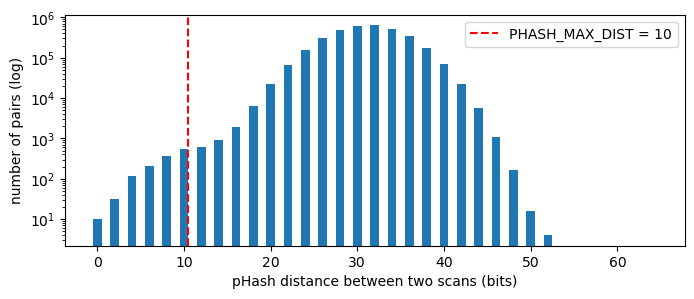

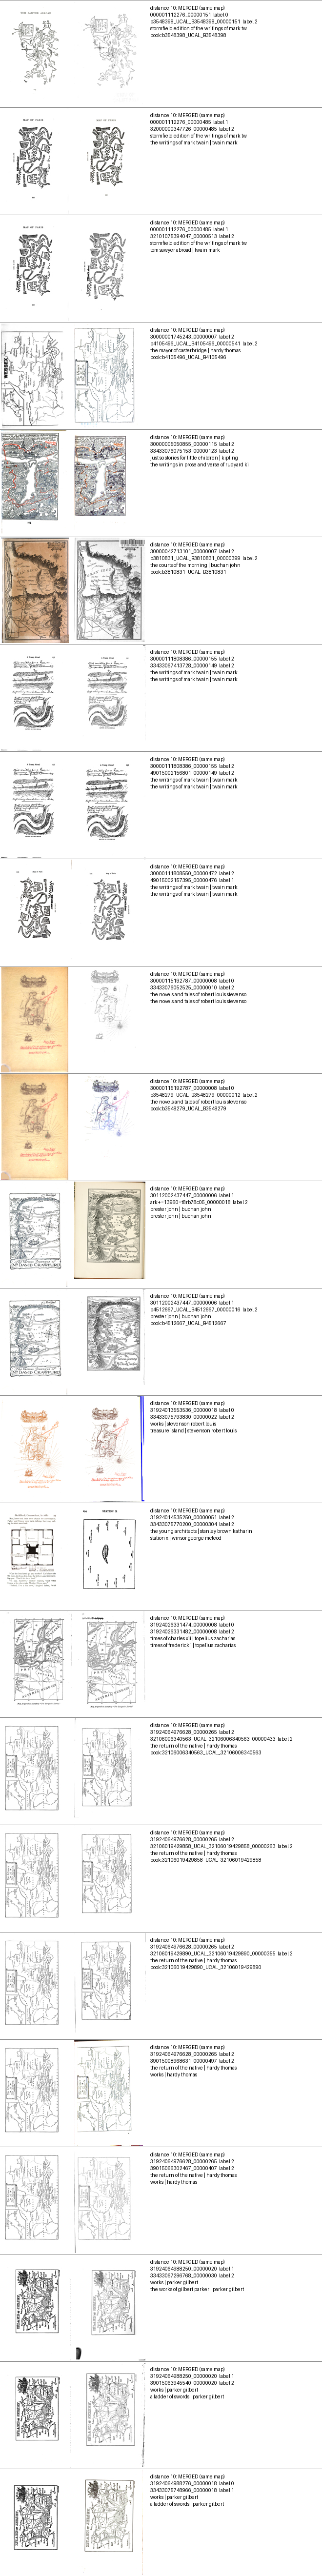

In [8]:
iu = np.triu_indices(len(df), k=1)
plt.figure(figsize=(8, 3))
plt.hist(dist[iu], bins=np.arange(66) - 0.5, log=True)
plt.axvline(PHASH_MAX_DIST + 0.5, color="red", ls="--", label=f"PHASH_MAX_DIST = {PHASH_MAX_DIST}")
plt.xlabel("pHash distance between two scans (bits)")
plt.ylabel("number of pairs (log)")
plt.legend()
plt.show()


def dedup_review_sheet(n_pairs=24, band=3):
    """Side-by-side thumbnails of the pairs whose distance is within `band` of the threshold."""
    i, j = np.where(np.triu(np.abs(dist - PHASH_MAX_DIST) <= band, k=1))
    if len(i) == 0:
        return None
    d = dist[i, j]
    order = np.argsort(np.abs(d - PHASH_MAX_DIST - 0.5), kind="stable")[:n_pairs]
    th, tw, text_w = 220, 150, 360
    sheet = Image.new("RGB", (2 * tw + text_w, th * len(order)), "white")
    draw = ImageDraw.Draw(sheet)
    for row, k in enumerate(order):
        a, b = df.iloc[i[k]], df.iloc[j[k]]
        for col, r in enumerate([a, b]):
            sheet.paste(thumbnail(r["src_path"], (tw - 4, th - 4)), (col * tw + 2, row * th + 2))
        verdict = "MERGED (same map)" if d[k] <= PHASH_MAX_DIST else "kept apart"
        draw.text((2 * tw + 8, row * th + 10),
                  f"distance {d[k]}: {verdict}\n{a['image_id']}  label {a['label_original']}\n"
                  f"{b['image_id']}  label {b['label_original']}\n{a['work_key'][:45]}\n{b['work_key'][:45]}",
                  fill="black")
        draw.line([(0, row * th), (sheet.width, row * th)], fill="gray")
    return sheet


review = dedup_review_sheet()
if review is None:
    print("No pairs near the threshold.")
else:
    display(review)

### Browse every merged map
Each row is one map: its kept scan first (green), then the other scans with their distance to it. Rows are sorted by the widest distance between any two scans of that map, so the merges most likely to be wrong come first. Long chains are the thing to look for: A looks like B and B looks like C, but A and C are different maps.

The first cell lists the merged maps; change `page` in the second cell to page through them.

In [9]:
CLUSTERS_PER_PAGE = 10   # maps per page
MAX_THUMBS = 8           # scans shown per map

# map -> its rows in df. .groups gives index labels, which equal positions because df has a 0..n-1 index
# (.indices would give positions within the filtered frame - the wrong rows)
members = {c: np.asarray(ix) for c, ix in df[df["n_scans"] > 1].groupby("dup_cluster").groups.items()}
spread = {c: int(dist[np.ix_(idx, idx)].max()) for c, idx in members.items()}  # widest pair within each map
cluster_order = sorted(members, key=lambda c: (-spread[c], c))              # most suspicious first
n_pages = -(-len(cluster_order) // CLUSTERS_PER_PAGE)
print(f"{len(cluster_order)} merged maps -> {n_pages} page(s) of {CLUSTERS_PER_PAGE}")


def show_clusters(page=0):
    sel = cluster_order[page * CLUSTERS_PER_PAGE:(page + 1) * CLUSTERS_PER_PAGE]
    if not sel:
        print(f"Page {page} is empty (pages run 0 to {n_pages - 1}).")
        return
    fig, axes = plt.subplots(len(sel), MAX_THUMBS, figsize=(1.9 * MAX_THUMBS, 3.0 * len(sel)), squeeze=False)
    for row, c in zip(axes, sel):
        kept_pos = df.index[df["image_id"] == rep[c]][0]
        order = [kept_pos] + [p for p in members[c] if p != kept_pos]
        for ax in row:
            ax.axis("off")
        row[0].text(0, 1.32, f"map {c}: {len(order)} scans, widest pair {spread[c]}, "
                             f"voted label {CLASS_NAMES[df.at[kept_pos, 'label']]}",
                    transform=row[0].transAxes, fontsize=9, fontweight="bold")
        for k, (ax, p) in enumerate(zip(row, order)):
            r = df.loc[p]
            ax.imshow(thumbnail(r["src_path"]))
            tag = "KEPT" if k == 0 else f"dist {dist[kept_pos, p]}"
            ax.set_title(f"{tag}, label {r['label_original']}\n{r['image_id']}", fontsize=7,
                         color="green" if k == 0 else "black")
    fig.subplots_adjust(hspace=0.55, wspace=0.05)
    plt.show()

276 merged maps -> 28 page(s) of 10


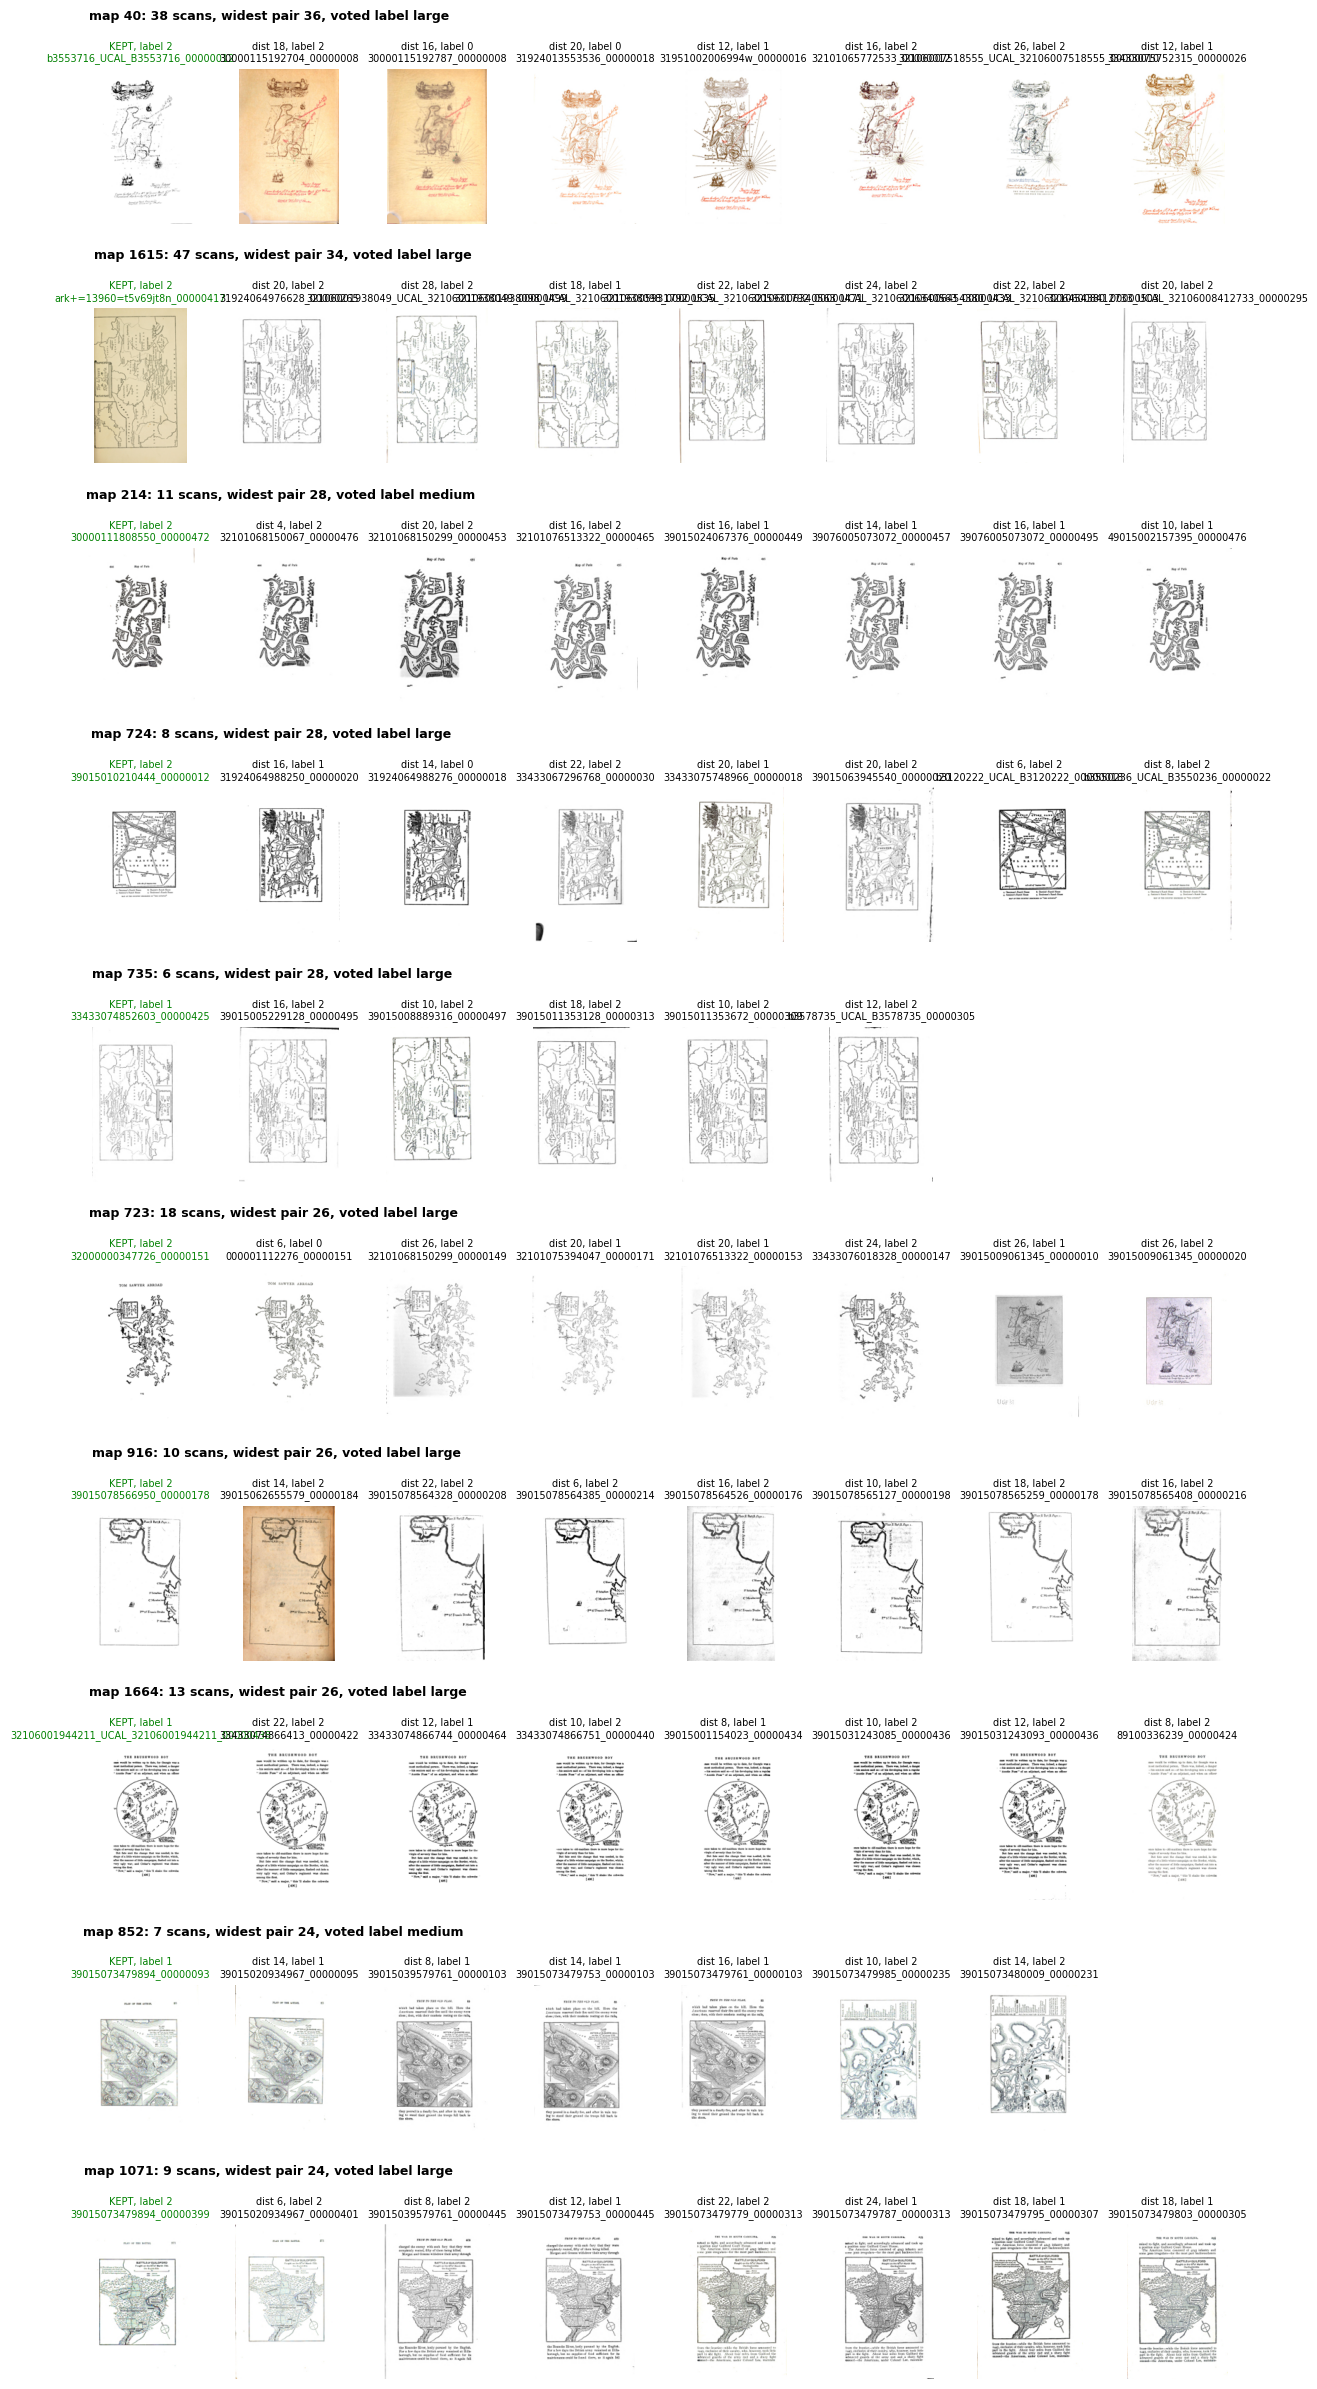

In [10]:
show_clusters(page=0)

## 5. Split groups
A **group** is everything connected by "same work" or "same map". This uses all scans, so a reprint can link two titles: *Treasure Island* and a collected *Novels and Tales of R. L. Stevenson* end up in one group. A whole group always goes to one split, which is what prevents train/test leakage.

In [11]:
uf = UnionFind(len(df))
for col in ["work_key", "dup_cluster"]:
    for idx in df.groupby(col).indices.values():
        for j in idx[1:]:
            uf.union(int(idx[0]), int(j))
df["group_id"] = uf.component_ids()

groups = (df[df["kept"]].groupby("group_id")
            .agg(maps=("image_id", "size"), works=("work_key", "nunique"), example=("work_key", "first"))
            .sort_values("maps", ascending=False))
print(f"{len(groups)} groups; the largest holds {groups['maps'].iloc[0] / groups['maps'].sum():.1%} of the maps")
display(groups.head())

853 groups; the largest holds 2.0% of the maps


,maps,works,example
group_id,,,
410,40,2,through russian snows | henty g a
393,31,11,stevenson s treasure island | stevenson robert...
30,26,1,report of traffic survey city of manchester n ...
315,23,2,with clive in india | henty g a
233,22,1,the lightning conductor discovers america | wi...


## 6. Stratified group split
Only kept scans are split here (one per map); rescans follow their map in section 7. Groups are assigned largest first. Each one goes to whichever split it brings closest to that split's target count for every class. Gaps are measured relative to class size, so the small Small class isn't drowned out by Large. The result keeps every group intact and the class mix roughly equal across splits.

In [12]:
def stratified_group_split(frame, fracs, seed):
    counts = pd.crosstab(frame["group_id"], frame["label"])   # groups x classes
    G = counts.to_numpy(dtype=float)
    class_tot = G.sum(axis=0)
    names = list(fracs)
    target = np.array([fracs[n] for n in names])[:, None] * class_tot[None, :]
    current = np.zeros_like(target)
    order = np.random.default_rng(seed).permutation(len(G))
    order = order[np.argsort(-G[order].sum(axis=1), kind="stable")]  # largest first, random among ties
    assign = np.empty(len(G), dtype=object)
    for g in order:
        before = ((current - target) / class_tot) ** 2
        after = ((current + G[g] - target) / class_tot) ** 2
        s = int(np.argmin((after - before).sum(axis=1)))  # split this group helps most
        current[s] += G[g]
        assign[g] = names[s]
    return frame["group_id"].map(dict(zip(counts.index, assign)))


def split_table(frame):
    """Images per split x class, with the class mix in parentheses."""
    t = pd.crosstab(frame["split"], frame["label"].map(CLASS_NAMES), margins=True, margins_name="total")
    t = t.reindex(index=["train", "val", "test", "total"], columns=[*CLASS_NAMES.values(), "total"], fill_value=0)
    pct = t.div(t["total"], axis=0).mul(100).round().astype(int)
    return t, t.astype(str) + " (" + pct.astype(str) + "%)"


kept = df[df["kept"]].copy()
kept["split"] = stratified_group_split(kept, {"train": TRAIN_FRAC, "val": VAL_FRAC, "test": TEST_FRAC}, SEED)
assert kept.groupby("group_id")["split"].nunique().max() == 1, "a group landed in two splits"
print("Maps per split:")
display(split_table(kept)[1])

Maps per split:


label,small,medium,large,total
split,,,,
train,120 (9%),251 (18%),1005 (73%),1376 (100%)
val,26 (9%),54 (18%),215 (73%),295 (100%)
test,26 (9%),54 (18%),215 (73%),295 (100%)
total,172 (9%),359 (18%),1435 (73%),1966 (100%)


## 7. Pad, resize, denoise, save
- **Target size** comes from the train split only: its median height/width ratio, at `TARGET_HEIGHT` pixels tall. Using train only keeps val and test from influencing preprocessing.
- Each image is **padded** (never stretched) to that ratio, then shrunk with area averaging, which also smooths out scan grain.
- Big JPEGs are decoded at reduced scale first (`draft`), which makes the 100-megapixel fold-outs quick.
- Light **non-local-means denoising** runs last, on the small image. It's most of the runtime (about half a second per image per core).

In [13]:
tr = kept[kept["split"] == "train"]
w, h = tr["orig_width"].to_numpy(float), tr["orig_height"].to_numpy(float)
if ROTATE_LANDSCAPE:
    w, h = np.minimum(w, h), np.maximum(w, h)
RATIO_HW = float(np.median(h / w))
TH = int(TARGET_HEIGHT or np.median(h))
TW = int(round(TH / RATIO_HW))
print(f"Target size: {TW} x {TH} (train median height/width = {RATIO_HW:.3f})")

Target size: 673 x 1024 (train median height/width = 1.522)


**Rescans (natural augmentation).** For every map whose kept scan is in train, up to `MAX_RESCANS_PER_MAP` of its other scans (picked at random when there are more) are processed too. They become `variant = "rescan"` rows saved in `train_rescans/<class>/`. A real rescan from another library, with its own paper tone, ink bleed and crop, is realistic variation that synthetic augmentation can only imitate. Maps in val and test keep only their kept scan, so no reprinted map gets counted several times in evaluation.

This cell **deletes `data/processed/`**, then writes kept scans to `<split>/<class>/` and rescans to `train_rescans/<class>/`.

In [14]:
def process_one(src, dst):
    """Load -> (rotate) -> pad -> resize -> denoise -> save. Returns an error message, or None."""
    try:
        with Image.open(src) as im:
            w, h = im.size
            ew, eh = (h, w) if (ROTATE_LANDSCAPE and w > h) else (w, h)
            s = min(TW / ew, TH / eh)                                  # final scale of the content
            im.draft("RGB", (int(w * s * 2) + 1, int(h * s * 2) + 1))  # decode at >= 2x the final size
            rgb = np.asarray(im.convert("RGB"))
        if ROTATE_LANDSCAPE and rgb.shape[1] > rgb.shape[0]:
            rgb = np.ascontiguousarray(np.rot90(rgb))                  # 90 deg counter-clockwise
        out = cv2.resize(pad_to_aspect(rgb, TH / TW, PAD_MODE), (TW, TH), interpolation=cv2.INTER_AREA)
        if DENOISE:
            bgr = cv2.cvtColor(out, cv2.COLOR_RGB2BGR)                 # OpenCV's denoiser expects BGR
            bgr = cv2.fastNlMeansDenoisingColored(bgr, None, DENOISE_STRENGTH, DENOISE_STRENGTH, 7, 21)
            out = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(out).save(dst)
    except Exception as e:  # report and keep going; one bad file shouldn't stop the run
        return f"{Path(src).name}: {e!r}"


# Kept scans: one per map, in every split
kept["variant"] = "original"
kept["source_id"] = kept["image_id"]  # every row points to its map's kept scan
parts = [kept]

# Rescans: other scans of maps whose kept scan is in train
if DEDUP and RESCANS_AS_AUGMENTATION:
    train_maps = set(kept.loc[kept["split"] == "train", "dup_cluster"])
    pool = df[~df["kept"] & df["dup_cluster"].isin(train_maps)]
    rescans = (pool.sample(frac=1, random_state=SEED)       # random pick when over the cap
                   .groupby("dup_cluster").head(MAX_RESCANS_PER_MAP)
                   .assign(split="train", variant="rescan"))
    rescans["source_id"] = rescans["dup_cluster"].map(rep)
    parts.append(rescans)
    print(f"{len(rescans)} rescans of {rescans['dup_cluster'].nunique()} train maps added to train "
          f"({len(pool) - len(rescans)} more left out by the cap of {MAX_RESCANS_PER_MAP} per map)")

rows = pd.concat(parts, ignore_index=True)
rows["label_name"] = rows["label"].map(CLASS_NAMES)
rows["rotated"] = ROTATE_LANDSCAPE & (rows["orig_width"] > rows["orig_height"])
folder = rows["split"].where(rows["variant"] == "original", "train_rescans")
rows["path"] = folder + "/" + rows["label_name"] + "/" + rows["image_id"] + OUTPUT_EXT

# Start clean so stale files from an earlier run can't leak in
assert OUT_DIR.parent == ROOT / "data" and OUT_DIR.name == "processed", OUT_DIR
shutil.rmtree(OUT_DIR, ignore_errors=True)
OUT_DIR.mkdir(parents=True)

jobs = [(src, OUT_DIR / p) for src, p in zip(rows["src_path"], rows["path"])]
errors = [e for e in parallel_map(lambda job: process_one(*job), jobs, "pad/resize/denoise") if e]
if errors:
    print(f"WARNING: {len(errors)} images failed and are left out:", *errors[:10], sep="\n  ")
    failed = {e.split(": ")[0] for e in errors}
    rows = rows[~rows["src_path"].map(lambda p: Path(p).name in failed)]

402 rescans of 216 train maps added to train (164 more left out by the cap of 4 per map)
pad/resize/denoise: 2368/2368 (305s)


## 8. Manifest and summaries
`manifest.csv` has one row per image, and `path` is relative to `data/processed/`. The `variant` column says what each row is:

| variant | where | what |
|---|---|---|
| `original` | every split | the kept scan of each map, exactly one per map |
| `rescan` | train only | another library's scan of a train map |
| `augmented` | train only | a synthetic copy, added by `augment.ipynb` |

`source_id` always points to the map's kept scan, so it identifies the map across all three variants. To load it later:

```python
m = pd.read_csv(OUT_DIR / "manifest.csv", keep_default_na=False)
train = m[m["split"] == "train"]       # all variants: train classifiers on this
maps = m[m["variant"] == "original"]   # one row per map: PCA, t-SNE, dataset plots
```

Also written: `duplicates.csv` (every input image, its cluster, whether it was kept), `dedup_review.png`, `split_summary.csv` (maps per split), and `preprocess_config.json` (settings and target size; `augment.ipynb` reads it).

In [15]:
rows["aug_params"] = ""
cols = ["image_id", "path", "split", "variant", "label", "label_name", "source_id", "group_id",
        "work_key", "book_id", "dup_cluster", "n_scans", "label_conflict", "orig_width", "orig_height",
        "rotated", "fictionality", "aug_params"]
manifest = rows[cols].sort_values(["split", "label", "source_id", "variant", "image_id"])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)

df.drop(columns=["src_path", "pixels"]).to_csv(OUT_DIR / "duplicates.csv", index=False)
if review is not None:
    review.save(OUT_DIR / "dedup_review.png")
maps_per_split, pretty = split_table(manifest[manifest["variant"] == "original"])
maps_per_split.to_csv(OUT_DIR / "split_summary.csv")

config = {
    "split_fracs": {"train": TRAIN_FRAC, "val": VAL_FRAC, "test": TEST_FRAC}, "seed": SEED,
    "dedup": DEDUP, "rescans_as_augmentation": RESCANS_AS_AUGMENTATION,
    "max_rescans_per_map": MAX_RESCANS_PER_MAP, "phash_max_dist": PHASH_MAX_DIST, "hash_crop": HASH_CROP,
    "target_width": TW, "target_height": TH, "train_median_aspect_hw": RATIO_HW,
    "rotate_landscape": ROTATE_LANDSCAPE, "pad_mode": PAD_MODE,
    "denoise": DENOISE, "denoise_strength": DENOISE_STRENGTH, "output_ext": OUTPUT_EXT,
    "excluded": sorted(EXCLUDE), "n_input": len(df),
    "n_maps": int((manifest["variant"] == "original").sum()),
    "n_rescans": int((manifest["variant"] == "rescan").sum()),
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(OUT_DIR / "preprocess_config.json").write_text(json.dumps(config, indent=2))

print(f"Wrote {len(manifest)} images and manifest.csv to {OUT_DIR}\n\nMaps per split:")
display(pretty)
tr = manifest[manifest["split"] == "train"]
print("Train rows by variant:")
display(pd.crosstab(tr["label_name"], tr["variant"], margins=True, margins_name="total")
          .reindex([*CLASS_NAMES.values(), "total"], fill_value=0)
          .rename_axis(index="class", columns=None))

Wrote 2368 images and manifest.csv to /home/uselessbian/281/281project/data/processed

Maps per split:


label,small,medium,large,total
split,,,,
train,120 (9%),251 (18%),1005 (73%),1376 (100%)
val,26 (9%),54 (18%),215 (73%),295 (100%)
test,26 (9%),54 (18%),215 (73%),295 (100%)
total,172 (9%),359 (18%),1435 (73%),1966 (100%)


Train rows by variant:


,original,rescan,total
class,,,
small,120,19,139
medium,251,109,360
large,1005,274,1279
total,1376,402,1778


## 9. Spot check
Five random processed training maps per class (kept scans only).

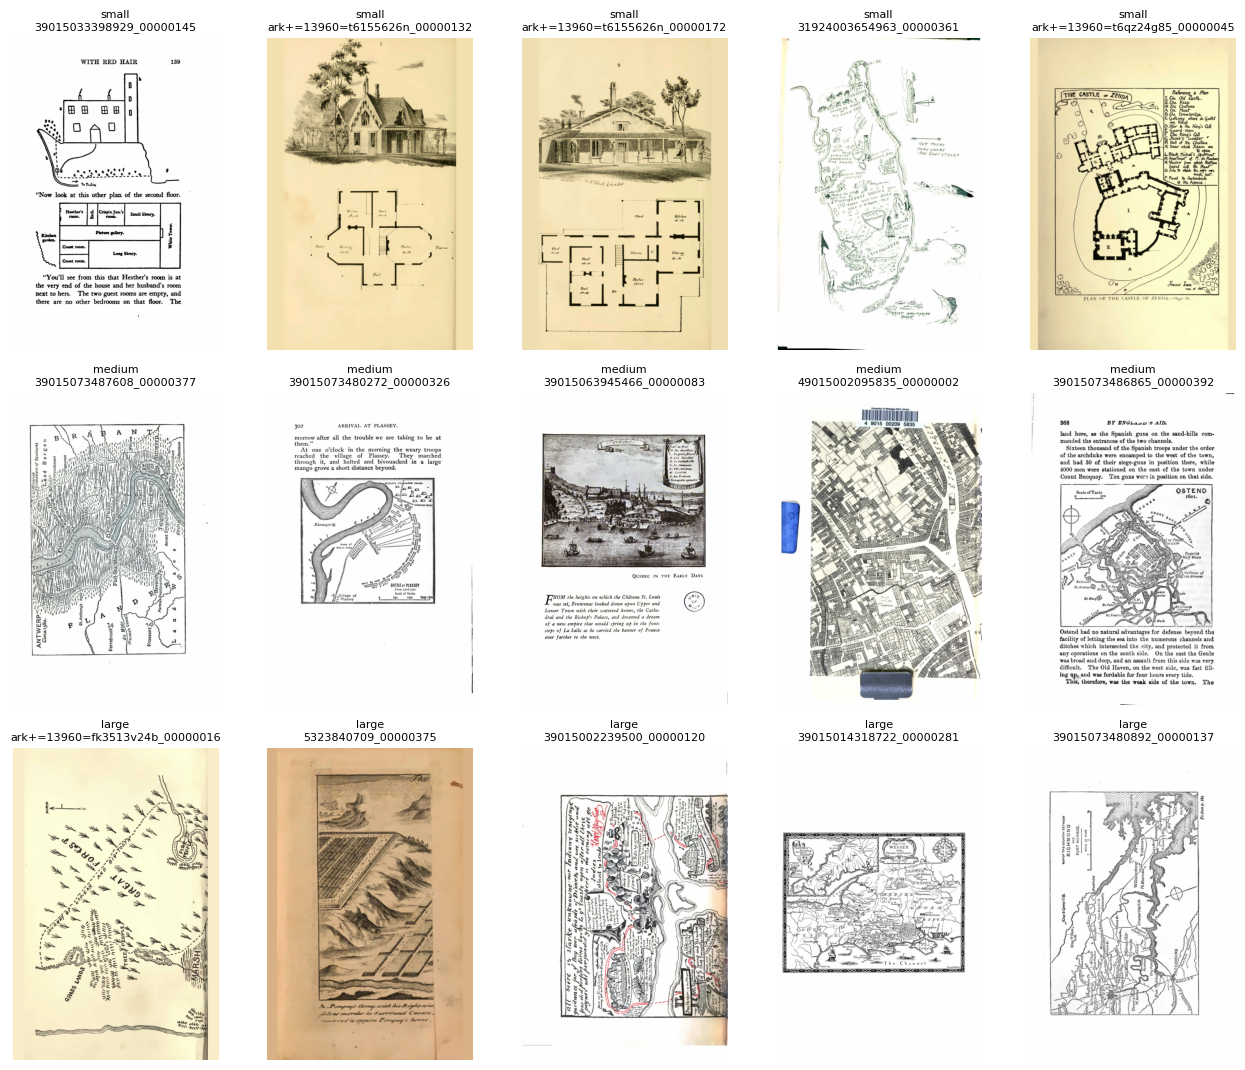

In [16]:
train_maps_m = manifest[(manifest["split"] == "train") & (manifest["variant"] == "original")]
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(13, 3.6 * len(CLASS_NAMES)))
for row, (label, name) in zip(axes, CLASS_NAMES.items()):
    pool = train_maps_m[train_maps_m["label"] == label]
    for ax in row:
        ax.axis("off")
    for ax, (_, r) in zip(row, pool.sample(min(5, len(pool)), random_state=0).iterrows()):
        ax.imshow(Image.open(OUT_DIR / r["path"]))
        ax.set_title(f"{name}\n{r['image_id']}", fontsize=8)
plt.tight_layout()
plt.show()

The three train maps with the most rescans, each shown as its kept scan followed by its rescans after processing. This is what the "natural augmentation" looks like.

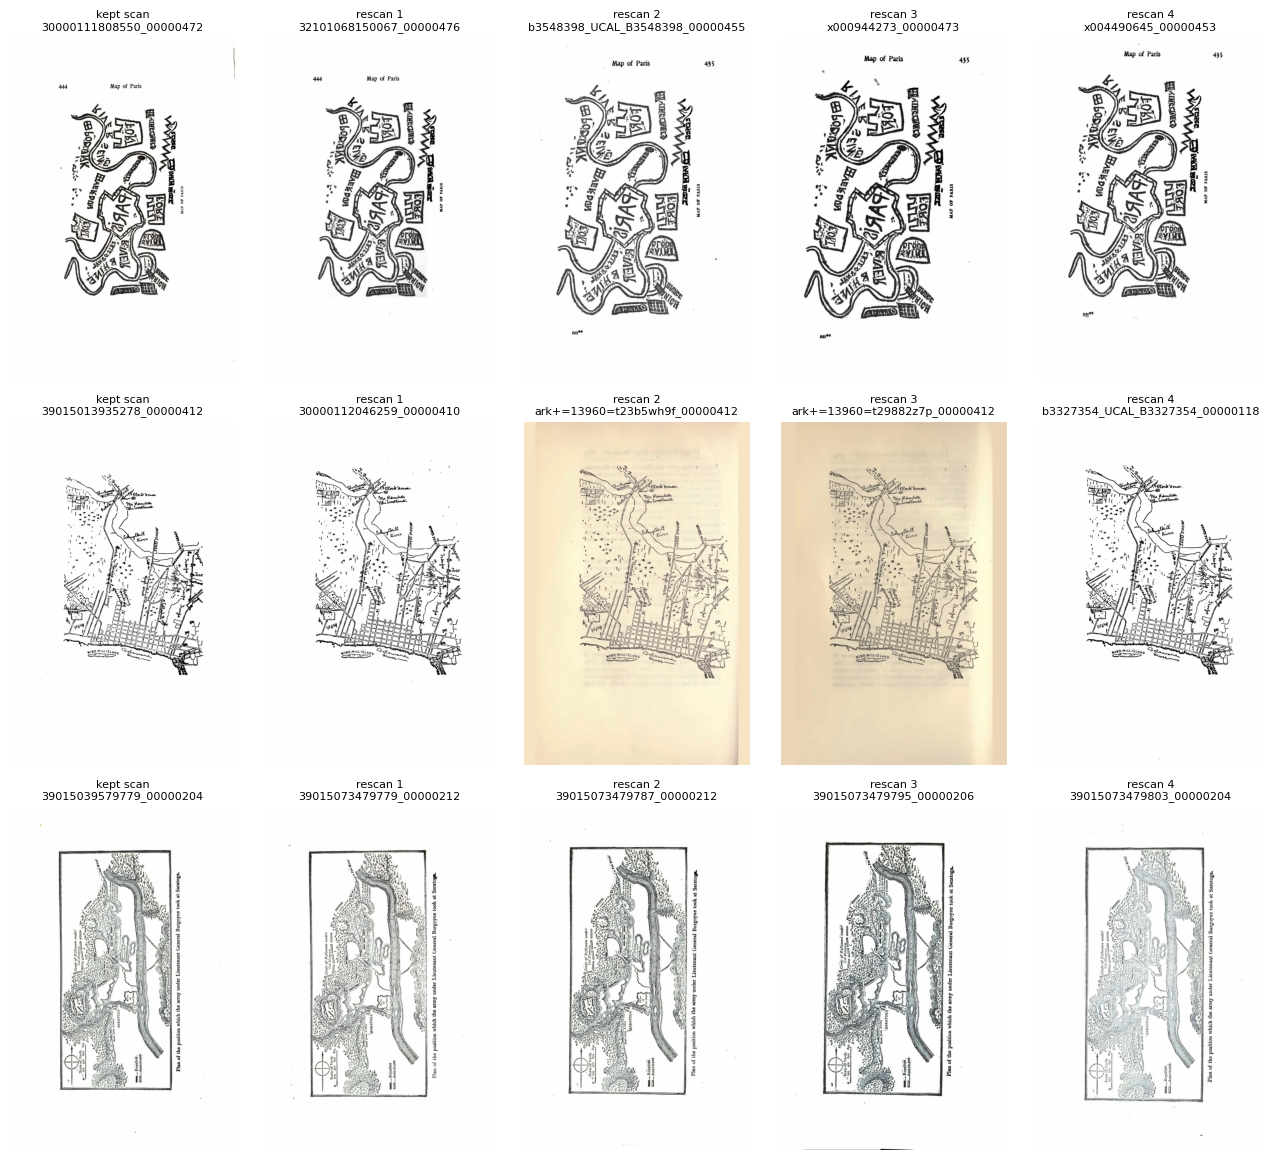

In [17]:
resc = manifest[manifest["variant"] == "rescan"]
if resc.empty:
    print("No rescans in train (RESCANS_AS_AUGMENTATION is off, or no train map has duplicate scans).")
else:
    per_map = resc["source_id"].value_counts()
    paths = manifest.set_index("image_id")["path"]
    ncol = 1 + per_map.iloc[0]
    fig, axes = plt.subplots(min(3, len(per_map)), ncol, figsize=(2.6 * ncol, 3.9 * min(3, len(per_map))), squeeze=False)
    for row, sid in zip(axes, per_map.index[:3]):
        ids = [sid, *resc.loc[resc["source_id"] == sid, "image_id"]]
        for ax in row:
            ax.axis("off")
        for k, (ax, i) in enumerate(zip(row, ids)):
            ax.imshow(Image.open(OUT_DIR / paths[i]))
            ax.set_title(("kept scan" if k == 0 else f"rescan {k}") + f"\n{i}", fontsize=8)
    plt.tight_layout()
    plt.show()